<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Two cities, three days, one careful clock

**Does “tomorrow’s weather” describe the same time window in Tokyo and Reykjavik?**
We will resolve two place names, compare a short temperature and precipitation
forecast, then reconstruct daily summaries in SQL. The weather comparison leads
to a less obvious question: which hours belong to a day?

This is a **live Open-Meteo forecast** walkthrough. The saved results were fetched
through the published TypeScript worker and the real VGI extension. Forecast
values are modeled weather, including any elapsed hours in today’s window; they
are not station observations. Historical reanalysis is a different modeled
product, and neither product alone supplies a forecast-error comparison.

Our evidence is a small bounded window, not a claim about either city’s climate.
Numerical interpretations and chart annotations are generated from returned rows.

## Choose the comparison

`FORECAST_DAYS` selects **1–5 provider days**, beginning with the API’s current
calendar day in the requested zone. `DAY_BOUNDARY="auto"` resolves the zone per
place; `"GMT"` aligns both to UTC. The returned interval columns are the authority
for the actual dates. Those intervals use the provider’s fixed offset, so they
need not match civil days across a daylight-saving transition.

Use two distinct place names and one model selector. We request Celsius, m/s and
mm explicitly. The hourly request includes one prior UTC day and one extra future
UTC day so each selected provider-day interval can be reconstructed. Edit a
parameter, then **Restart Kernel → Run All**. The fresh run makes new public API
requests; there is no replay or fallback.

In [1]:
PLACES = ["Tokyo", "Reykjavik"]
FORECAST_DAYS = 3              # 1–5 days, starting with each requested zone's current day
DAY_BOUNDARY = "auto"         # "auto" for local provider days, or "GMT" for UTC days
MODEL = "best_match"          # One selector; this does not identify a unique model run

In [2]:
from pathlib import Path
import os
import sys
from datetime import UTC, datetime
os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd()
sys.path.insert(0, str(NOTEBOOK_DIR))
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from notebook_support import PALETTE, finish_chart, number, prepare, prose, sql_text, theme
prepare(PLACES, FORECAST_DAYS, DAY_BOUNDARY, MODEL)
places_sql = ", ".join(f"({sql_text(p)})" for p in PLACES)
boundary_sql, model_sql = sql_text(DAY_BOUNDARY), sql_text(MODEL)
run_started = datetime.now(UTC)
colors = dict(zip(PLACES, PALETTE))
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-open-meteo/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-open-meteo/notebooks/pyproject.toml.

In [3]:
prose(f"**LIVE · Open-Meteo public API**  \nRun started **{run_started:%Y-%m-%d %H:%M:%S} UTC**. "
      f"Selected boundary: **{DAY_BOUNDARY}**; **{FORECAST_DAYS} days per place**. "
      "The response retrieval timestamps appear below; this run-start clock is not a model issue time.")

**LIVE · Open-Meteo public API**  
Run started **2026-11-14 04:11:17 UTC**. Selected boundary: **auto**; **3 days per place**. The response retrieval timestamps appear below; this run-start clock is not a model issue time.

## Start the pinned worker revision

The literal command below runs the small [Git launcher](github_worker.ts). It fetches
public commit `67b18aedaf207cfea721121968bbec4ea0e0f735` (release v0.4.0), installs
its frozen Bun dependencies once in the user cache, and starts `src/bin/worker.ts`.
The checkout is managed by the launcher; this notebook needs only its companions,
Bun and Git. Installation messages use stderr so stdout remains the VGI protocol.

This release has no native GitHub assets and its declared npm package was unavailable
when verified. No local worker binary is substituted. The SQL refreshes and loads
VGI, then attaches the worker's catalog. Ordinary in-memory tables persist across
JupySQL cursors.

In [4]:
%%sql
FORCE INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'open_meteo' AS weather (TYPE vgi, LOCATION 'bun run github_worker.ts Query-farm/vgi-open-meteo 67b18aedaf207cfea721121968bbec4ea0e0f735 src/bin/worker.ts');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


## Start with places, not guessed coordinates

Geocoding returns the first matching candidate for each name. Review the country
and timezone: a successful lookup is not proof that an ambiguous name identified
the intended place. The selected coordinates then flow into the weather functions
through a `LATERAL` join.

In [5]:
%%sql places <<
CREATE TABLE places AS
SELECT p.place, g.name AS resolved_name, g.country, g.latitude, g.longitude, g.timezone
FROM (VALUES {{ places_sql }}) AS p(place),
     LATERAL weather.main.geocoding(p.place, count := 1) AS g;
SELECT * FROM places ORDER BY place;

In [6]:
display(places)
if len(places) != len(PLACES) or places.place.nunique() != len(PLACES):
    raise ValueError("A required place did not resolve uniquely. Review PLACES and rerun; no substitute data was used.")

,place,resolved_name,country,latitude,longitude,timezone
0,Reykjavik,Reykjavik,Iceland,64.13548,-21.89541,Atlantic/Reykjavik
1,Tokyo,Tokyo,Japan,35.68950,139.69171,Asia/Tokyo


## Fetch once, keep the provenance

We materialize the padded **hourly UTC** forecast and the selected **daily**
forecast separately. Later charts and calculations read these tables; they do
not call Open-Meteo again. SQL projection keeps the saved table small, although
the worker requests its fixed upstream variable list.

`best_match` is a requested selection, potentially blending sources. The returned
grid coordinate can differ from the geocoded city coordinate. `retrieved_at`
records when the worker received each response; hourly and daily responses are
not an atomic snapshot and do not supply a unique forecast issuance time.

In [7]:
%%sql
CREATE TABLE hourly AS
SELECT p.place, h.time, h.temperature_2m, h.precipitation, h.wind_speed_10m,
       h.interval_start, h.interval_end, h.interval_seconds,
       h.model_selection, h.source_endpoint, h.retrieved_at,
       h.grid_latitude, h.grid_longitude, h.response_timezone, h.utc_offset_seconds
FROM places p,
     LATERAL weather.main.forecast_hourly(
       p.latitude, p.longitude, forecast_days := {{ FORECAST_DAYS + 1 }}, past_days := 1,
       timezone := 'GMT', temperature_unit := 'celsius',
       wind_speed_unit := 'ms', precipitation_unit := 'mm', model := {{ model_sql }}
     ) h;

CREATE TABLE daily AS
SELECT p.place, d.date, d.time, d.temperature_2m_min, d.temperature_2m_max,
       d.precipitation_sum, d.wind_speed_10m_max,
       d.interval_start, d.interval_end, d.interval_seconds,
       d.model_selection, d.source_endpoint, d.retrieved_at,
       d.grid_latitude, d.grid_longitude, d.response_timezone, d.utc_offset_seconds
FROM places p,
     LATERAL weather.main.forecast_daily(
       p.latitude, p.longitude, forecast_days := {{ FORECAST_DAYS }},
       timezone := {{ boundary_sql }}, temperature_unit := 'celsius',
       wind_speed_unit := 'ms', precipitation_unit := 'mm', model := {{ model_sql }}
     ) d;

,Count


In [8]:
%%sql provenance <<
SELECT 'hourly' AS product, place, model_selection, response_timezone,
       grid_latitude, grid_longitude, min(retrieved_at) AS retrieved_at_utc,
       min(time) AS first_timestamp_utc, max(time) AS last_timestamp_utc,
       count(*) AS rows, count(temperature_2m) AS temperature_values,
       count(precipitation) AS precipitation_values
FROM hourly GROUP BY ALL
UNION ALL
SELECT 'daily', place, model_selection, response_timezone,
       grid_latitude, grid_longitude, min(retrieved_at), min(time), max(time),
       count(*), count(*) FILTER (WHERE temperature_2m_min IS NOT NULL AND temperature_2m_max IS NOT NULL),
       count(precipitation_sum)
FROM daily GROUP BY ALL
ORDER BY product, place;

In [9]:
display(provenance)
if set(provenance.place) != set(PLACES) or len(provenance) != 4:
    raise ValueError("A required forecast product is missing. No fallback was used.")
if not (provenance.loc[provenance['product'].eq('daily'), 'rows'] == FORECAST_DAYS).all():
    raise ValueError("The API did not return the selected number of daily rows.")
received = pd.to_datetime(provenance.retrieved_at_utc, utc=True)
source = f"Open-Meteo via local VGI · responses received {received.min():%Y-%m-%d %H:%M:%S}–{received.max():%H:%M:%S} UTC"
missing_t = int((provenance.rows - provenance.temperature_values).sum())
missing_p = int((provenance.rows - provenance.precipitation_values).sum())
prose(f"The materialized products contain **{int(provenance.rows.sum())} rows**. "
      f"The coverage table reports **{missing_t} missing temperature rows** and **{missing_p} missing precipitation rows** "
      "(daily temperature requires both extremes). Missing values stay missing; they are never treated as dry weather.")

,product,place,model_selection,response_timezone,grid_latitude,grid_longitude,retrieved_at_utc,first_timestamp_utc,last_timestamp_utc,rows,temperature_values,precipitation_values
0,daily,Reykjavik,best_match,Atlantic/Reykjavik,64.12922,-21.883698,2026-11-14 04:11:22.610000+00:00,2026-11-14 00:00:00+00:00,2026-11-16 00:00:00+00:00,3,3,3
1,daily,Tokyo,best_match,Asia/Tokyo,35.70000,139.687500,2026-11-14 04:11:22.610000+00:00,2026-11-13 15:00:00+00:00,2026-11-15 15:00:00+00:00,3,3,3
2,hourly,Reykjavik,best_match,GMT,64.12922,-21.883698,2026-11-14 04:11:22.548000+00:00,2026-11-13 00:00:00+00:00,2026-11-17 23:00:00+00:00,120,120,120
3,hourly,Tokyo,best_match,GMT,35.70000,139.687500,2026-11-14 04:11:22.548000+00:00,2026-11-13 00:00:00+00:00,2026-11-17 23:00:00+00:00,120,120,120


The materialized products contain **246 rows**. The coverage table reports **0 missing temperature rows** and **0 missing precipitation rows** (daily temperature requires both extremes). Missing values stay missing; they are never treated as dry weather.

## What exactly is a day?

A daily `date` is a provider calendar label. `interval_start` and `interval_end`
identify its physical window, **start inclusive and end exclusive**. With local
boundaries, the same label can refer to different UTC intervals. The first selected
date can also differ between places when a request arrives between their midnights.

The chart shows the **first returned day for each place** on one UTC axis. It does
not shift the forecast timestamps by the response offset.

In [10]:
%%sql boundaries <<
SELECT place, date AS provider_date, response_timezone,
       utc_offset_seconds / 3600.0 AS offset_hours,
       interval_start, interval_end,
       epoch(interval_end) - epoch(interval_start) AS seconds_in_day
FROM daily
QUALIFY row_number() OVER (PARTITION BY place ORDER BY date) = 1
ORDER BY place;

,place,provider_date,response_timezone,offset_hours,interval_start,interval_end,seconds_in_day
0,Reykjavik,2026-11-14,Atlantic/Reykjavik,0.0,2026-11-14 00:00:00+00:00,2026-11-15 00:00:00+00:00,86400.0
1,Tokyo,2026-11-14,Asia/Tokyo,9.0,2026-11-13 15:00:00+00:00,2026-11-14 15:00:00+00:00,86400.0


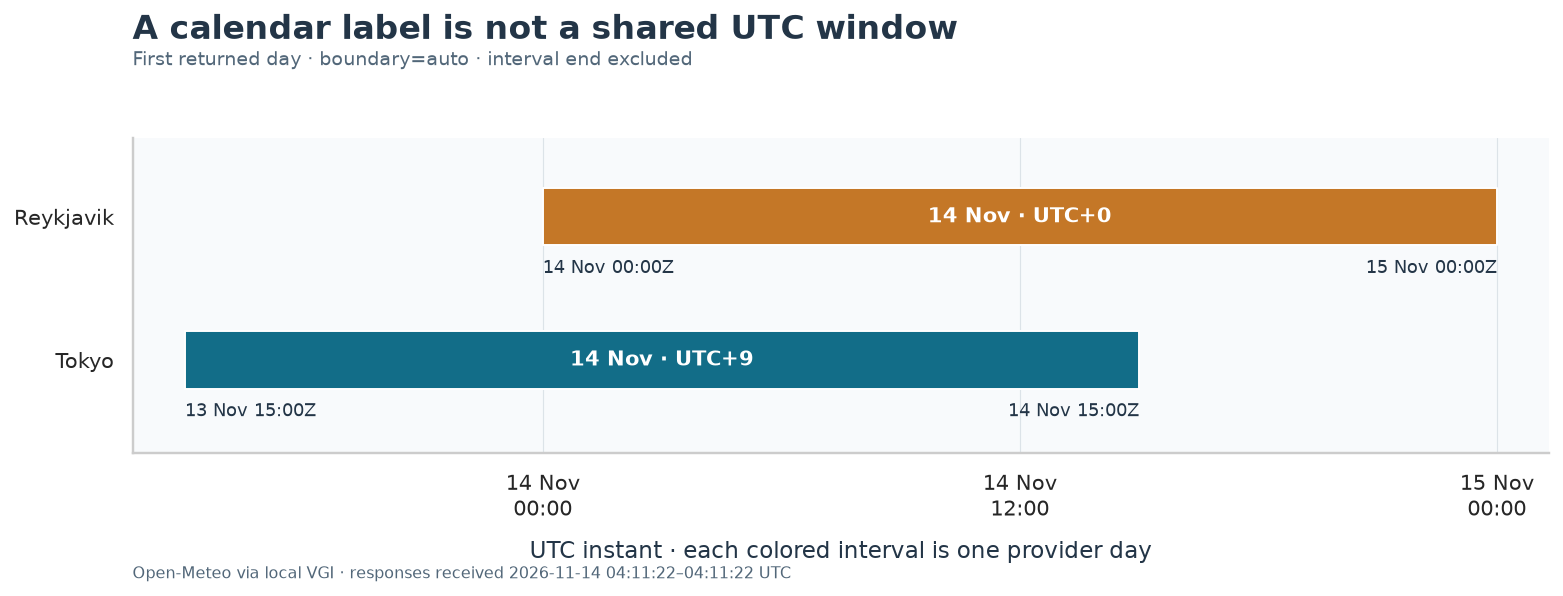

In [11]:
display(boundaries)
if not boundaries.seconds_in_day.eq(86400).all():
    raise ValueError("Unexpected provider-day duration; review interval semantics before aggregating.")
fig, ax = plt.subplots(figsize=(11.5, 4.2))
for i, place in enumerate(PLACES):
    row = boundaries.loc[boundaries.place.eq(place)].iloc[0]
    start, end = pd.Timestamp(row.interval_start), pd.Timestamp(row.interval_end)
    ax.broken_barh([(mdates.date2num(start), (end-start).total_seconds()/86400)], (i-.2,.4), facecolors=colors[place])
    ax.text(mdates.date2num(start+(end-start)/2), i,
            f"{pd.Timestamp(row.provider_date):%d %b} · UTC{row.offset_hours:+g}",
            ha='center', va='center', color='white', weight='bold', fontsize=11)
    ax.annotate(f"{start:%d %b %H:%M}Z", (mdates.date2num(start), i-.23), xytext=(0,-12),
                textcoords='offset points', ha='left', fontsize=9)
    ax.annotate(f"{end:%d %b %H:%M}Z", (mdates.date2num(end), i-.23), xytext=(0,-12),
                textcoords='offset points', ha='right', fontsize=9)
ax.set_yticks(range(len(PLACES)), PLACES)
ax.set_ylim(-.65, len(PLACES)-.45)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0,12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))
ax.set_xlabel('UTC instant · each colored interval is one provider day', labelpad=9)
ax.grid(axis='y', visible=False)
ax.margins(x=.04)
finish_chart(fig, 'A calendar label is not a shared UTC window',
             f"First returned day · boundary={DAY_BOUNDARY} · interval end excluded", source)

In [12]:
offsets = ', '.join(f"{r.place}: UTC{r.offset_hours:+g}" for r in boundaries.itertuples())
start_gap = (pd.to_datetime(boundaries.interval_start, utc=True).max()-pd.to_datetime(boundaries.interval_start, utc=True).min()).total_seconds()/3600
prose(f"The returned offsets are **{offsets}**. Their first day starts are **{start_gap:g} hours apart** in UTC. "
      "Compare these interval columns before joining daily products by date; equal labels alone do not establish equal exposure windows.")

The returned offsets are **Reykjavik: UTC+0, Tokyo: UTC+9**. Their first day starts are **9 hours apart** in UTC. Compare these interval columns before joining daily products by date; equal labels alone do not establish equal exposure windows.

## Compare the weather on the same clock

The next plot keeps **UTC on both city axes**, with shared temperature scales and
shared precipitation scales. Each city is clipped to its selected daily window,
so the different starts remain visible. Temperature is an instantaneous value at
`time`. Each precipitation bar spans the **preceding hour**, ending at `time`;
mm means liquid-water equivalent, including frozen precipitation.

The window begins at midnight rather than at retrieval, so some rows can describe
elapsed hours. They remain outputs of the forecast product, not observations.

In [13]:
%%sql trace <<
WITH windows AS (
  SELECT place, min(interval_start) AS window_start, max(interval_end) AS window_end
  FROM daily GROUP BY place
)
SELECT h.place, h.time, h.interval_start, h.interval_end,
       CASE WHEN h.time < w.window_end THEN h.temperature_2m END AS temperature_c,
       CASE WHEN h.interval_start >= w.window_start THEN h.precipitation END AS precipitation_mm,
       w.window_start, w.window_end
FROM hourly h JOIN windows w USING (place)
WHERE h.time >= w.window_start AND h.time <= w.window_end
ORDER BY h.place, h.time;

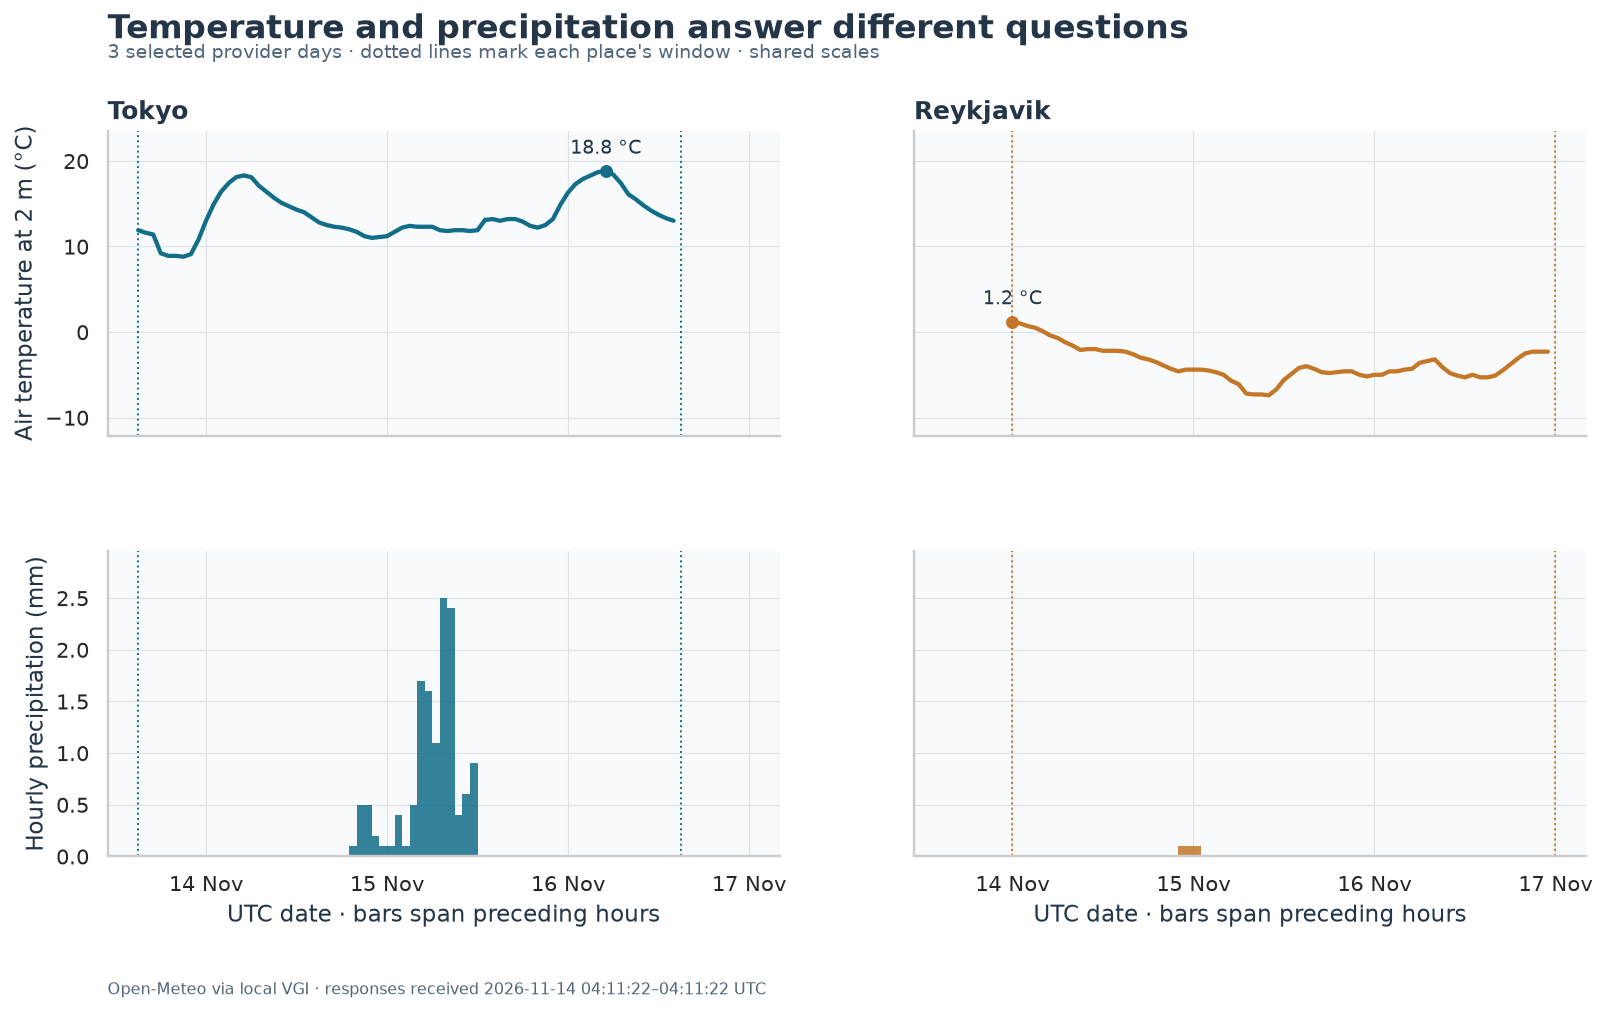

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.3), sharex=True, sharey='row')
for column, place in enumerate(PLACES):
    data = trace.loc[trace.place.eq(place)].copy()
    if data.empty:
        raise ValueError(f"No hourly values cover {place}'s selected days.")
    time = pd.to_datetime(data.time, utc=True)
    rain_start = pd.to_datetime(data.interval_start, utc=True)
    axes[0,column].plot(time, data.temperature_c, color=colors[place], lw=2.2)
    axes[0,column].set_title(place, loc='left', weight='bold', fontsize=13)
    valid = data.temperature_c.dropna()
    if not valid.empty:
        peak_index = valid.idxmax()
        axes[0,column].scatter(time.loc[peak_index], data.loc[peak_index,'temperature_c'], s=32, color=colors[place], zorder=3)
        axes[0,column].annotate(f"{valid.max():.1f} °C", (time.loc[peak_index],valid.max()),
            xytext=(0,9), textcoords='offset points', ha='center', fontsize=10)
    axes[1,column].bar(rain_start, data.precipitation_mm, width=1/24, align='edge',
                       color=colors[place], alpha=.85, linewidth=0)
    if data.precipitation_mm.notna().any() and data.precipitation_mm.max() == 0:
        axes[1,column].text(.5,.5,'All available hourly amounts are 0 mm',
                             transform=axes[1,column].transAxes, ha='center', fontsize=9)
    for row in range(2):
        axes[row,column].axvline(pd.Timestamp(data.window_start.iloc[0]), color=colors[place], ls=':', lw=1)
        axes[row,column].axvline(pd.Timestamp(data.window_end.iloc[0]), color=colors[place], ls=':', lw=1)
        axes[row,column].xaxis.set_major_locator(mdates.DayLocator())
        axes[row,column].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    axes[1,column].set_xlabel('UTC date · bars span preceding hours')
axes[0,0].set_ylabel('Air temperature at 2 m (°C)')
axes[1,0].set_ylabel('Hourly precipitation (mm)')
axes[0,0].margins(y=.18)
axes[1,0].set_ylim(bottom=0, top=max(.5, trace.precipitation_mm.max()*1.18 if trace.precipitation_mm.notna().any() else .5))
finish_chart(fig, 'Temperature and precipitation answer different questions',
             f"{FORECAST_DAYS} selected provider days · dotted lines mark each place's window · shared scales", source)

## Rebuild a daily summary without moving the clock

Temperature samples belong to `[day start, day end)`. To total hourly
precipitation, we require the **entire preceding-hour interval** to fall inside
the day: its start is at or after day start, and its end is at or before day end.
That includes the amount ending at the next midnight and excludes the one ending
at the current midnight.

The query reports coverage separately for each variable and only calculates a
complete-day hourly statistic when all 24 values exist. Daily source values stay
visible alongside the reconstruction. We do not average daily highs and lows
into a supposed daily mean.

In [15]:
%%sql daily_summary <<
CREATE TABLE daily_reconstruction AS
SELECT d.place, d.date, d.interval_start AS day_start, d.interval_end AS day_end,
       d.temperature_2m_min AS provider_low_c, d.temperature_2m_max AS provider_high_c,
       d.precipitation_sum AS provider_precip_mm,
       count(h.temperature_2m) FILTER (WHERE h.time < d.interval_end) AS temperature_hours,
       count(h.precipitation) FILTER (WHERE h.interval_start >= d.interval_start) AS precipitation_hours,
       CASE WHEN count(h.temperature_2m) FILTER (WHERE h.time < d.interval_end) = 24
         THEN min(h.temperature_2m) FILTER (WHERE h.time < d.interval_end) END AS hourly_low_c,
       CASE WHEN count(h.temperature_2m) FILTER (WHERE h.time < d.interval_end) = 24
         THEN max(h.temperature_2m) FILTER (WHERE h.time < d.interval_end) END AS hourly_high_c,
       CASE WHEN count(h.precipitation) FILTER (WHERE h.interval_start >= d.interval_start) = 24
         THEN sum(h.precipitation) FILTER (WHERE h.interval_start >= d.interval_start) END AS hourly_precip_mm
FROM daily d LEFT JOIN hourly h
  ON h.place = d.place AND h.time >= d.interval_start AND h.time <= d.interval_end
GROUP BY ALL;
SELECT place, date, temperature_hours, precipitation_hours,
       round(provider_low_c, 1) AS provider_low_c, round(provider_high_c, 1) AS provider_high_c,
       round(hourly_low_c, 1) AS hourly_low_c, round(hourly_high_c, 1) AS hourly_high_c,
       round(provider_precip_mm, 2) AS provider_precip_mm,
       round(hourly_precip_mm, 2) AS hourly_precip_mm,
       round(hourly_precip_mm - provider_precip_mm, 3) AS precipitation_difference_mm
FROM daily_reconstruction ORDER BY place, date;

In [16]:
display(daily_summary)
complete = daily_summary.temperature_hours.eq(24) & daily_summary.precipitation_hours.eq(24)
compared = daily_summary.precipitation_difference_mm.dropna()
max_difference = compared.abs().max() if not compared.empty else np.nan
prose(f"**{int(complete.sum())} of {len(daily_summary)} selected days** have all 24 temperature samples and precipitation intervals. "
      f"The largest absolute difference between the hourly precipitation reconstruction and the daily product is "
      f"**{number(max_difference, 3)} mm** across the {len(compared)} comparable days. "
      "Independent retrievals, upstream interpolation and rounding can affect agreement. A mismatch is a prompt to inspect intervals and provenance, not evidence of observed forecast error.")

,place,date,temperature_hours,precipitation_hours,provider_low_c,provider_high_c,hourly_low_c,hourly_high_c,provider_precip_mm,hourly_precip_mm,precipitation_difference_mm
0,Reykjavik,2026-11-14,24,24,-4.6,1.2,-4.6,1.2,0.3,0.2,-0.1
1,Reykjavik,2026-11-15,24,24,-7.4,-4.0,-7.4,-4.0,0.2,0.1,-0.1
2,Reykjavik,2026-11-16,24,24,-5.8,-2.3,-5.3,-2.3,0.0,0.0,0.0
3,Tokyo,2026-11-14,24,24,8.8,18.3,8.8,18.3,0.0,0.0,0.0
4,Tokyo,2026-11-15,24,24,11.0,13.2,11.0,13.2,13.7,13.7,0.0
5,Tokyo,2026-11-16,24,24,12.2,18.9,12.2,18.8,0.0,0.0,0.0


**6 of 6 selected days** have all 24 temperature samples and precipitation intervals. The largest absolute difference between the hourly precipitation reconstruction and the daily product is **0.100 mm** across the 6 comparable days. Independent retrievals, upstream interpolation and rounding can affect agreement. A mismatch is a prompt to inspect intervals and provenance, not evidence of observed forecast error.

In [17]:
%%sql checks <<
SELECT
  (SELECT count(*) = count(DISTINCT (place, time)) FROM hourly) AS unique_hourly_keys,
  (SELECT count(*) = count(DISTINCT (place, date)) FROM daily) AS unique_daily_keys,
  (SELECT count(*) FILTER (WHERE interval_end <> time OR interval_seconds <> 3600
       OR interval_start <> time - INTERVAL '1 hour') = 0 FROM hourly) AS preceding_hour_support,
  (SELECT count(*) FILTER (WHERE temperature_2m_min > temperature_2m_max) = 0 FROM daily) AS ordered_temperature_extremes,
  (SELECT count(*) FILTER (WHERE precipitation < 0) = 0 FROM hourly) AS nonnegative_precipitation,
  (SELECT count(*) FILTER (WHERE temperature_hours > 24 OR precipitation_hours > 24) = 0
       FROM daily_reconstruction) AS no_double_counted_hours;

In [18]:
display(checks)
if not checks.iloc[0].all():
    raise ValueError("A structural weather check failed; inspect the diagnostic table before interpreting results.")

,unique_hourly_keys,unique_daily_keys,preceding_hour_support,ordered_temperature_extremes,nonnegative_precipitation,no_double_counted_hours
0,True,True,True,True,True,True


## Read the daily comparison with its boundaries attached

The temperature segment is the provider’s low-to-high range, not an uncertainty
interval. The precipitation bars are provider daily water-equivalent totals. Both
panels use the same city/date rows; their units stay on separate axes. Incomplete
provider values are labeled rather than drawn as zero.

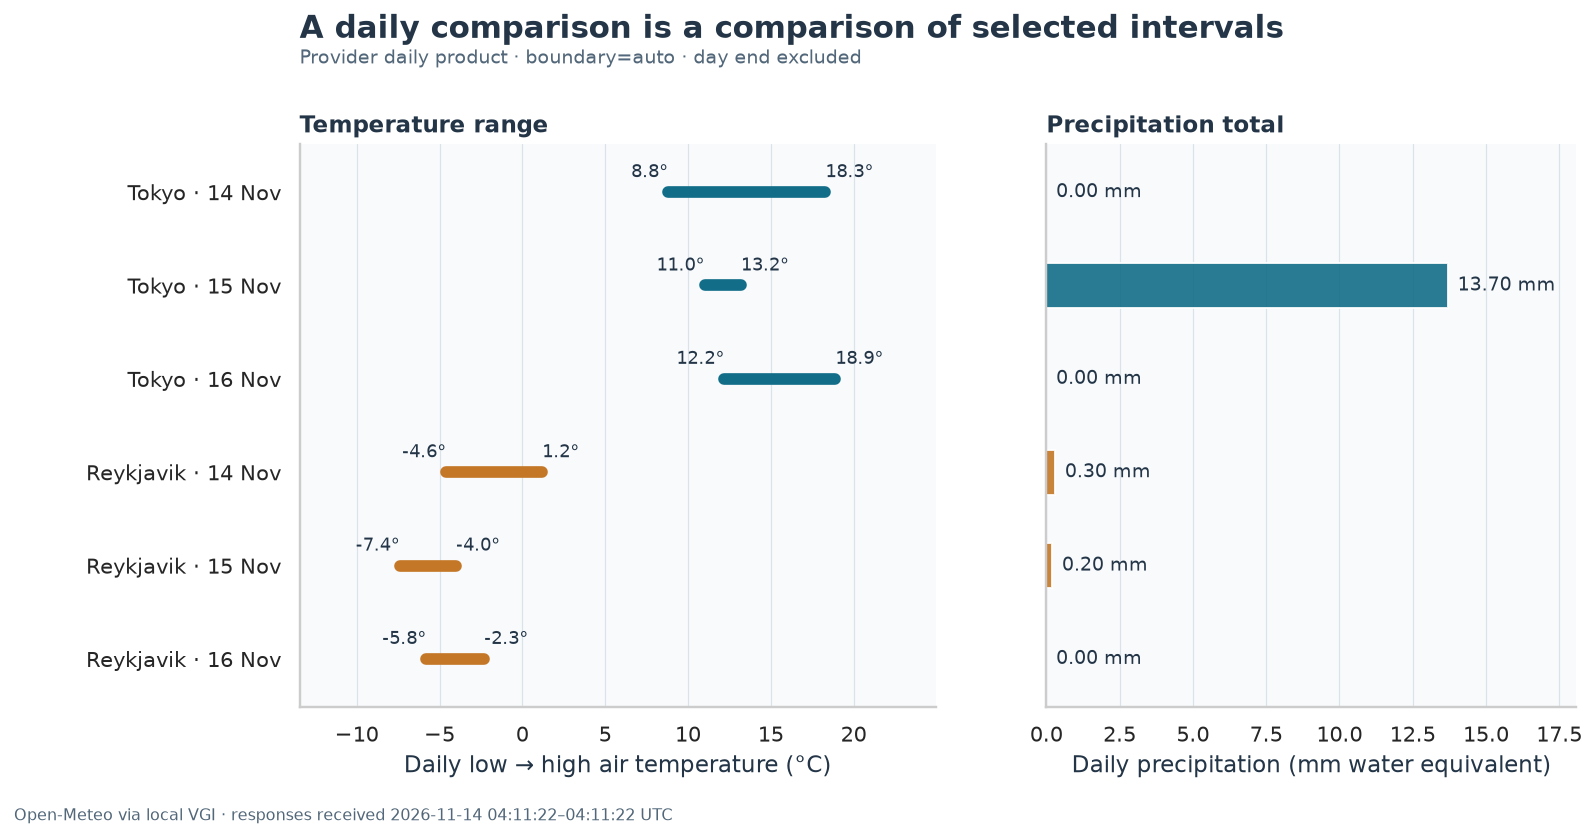

In [19]:
plot_data = daily_summary.copy()
plot_data['place_order'] = plot_data.place.map({p:i for i,p in enumerate(PLACES)})
plot_data = plot_data.sort_values(['place_order','date']).reset_index(drop=True)
fig, axes = plt.subplots(1,2,figsize=(12,6),sharey=True,gridspec_kw={'width_ratios':[1.2,1]})
labels=[]
for i,row in plot_data.iterrows():
    labels.append(f"{row.place} · {pd.Timestamp(row.date):%d %b}")
    color=colors[row.place]
    if pd.notna(row.provider_low_c) and pd.notna(row.provider_high_c):
        axes[0].plot([row.provider_low_c,row.provider_high_c],[i,i],lw=6,solid_capstyle='round',color=color)
        axes[0].text(row.provider_low_c,i-.16,f"{row.provider_low_c:.1f}°",ha='right',fontsize=9)
        axes[0].text(row.provider_high_c,i-.16,f"{row.provider_high_c:.1f}°",ha='left',fontsize=9)
    else:
        axes[0].text(.5,i,'Unavailable',transform=axes[0].get_yaxis_transform(),ha='center')
    if pd.notna(row.provider_precip_mm):
        axes[1].barh(i,row.provider_precip_mm,height=.48,color=color,alpha=.9)
        axes[1].annotate(f"{row.provider_precip_mm:.2f} mm",(row.provider_precip_mm,i),
                          xytext=(5,0),textcoords='offset points',va='center',fontsize=10)
    else:
        axes[1].text(0,i,'Unavailable',va='center')
axes[0].set_yticks(range(len(labels)),labels)
axes[0].invert_yaxis()
axes[0].set_xlabel('Daily low → high air temperature (°C)')
axes[1].set_xlabel('Daily precipitation (mm water equivalent)')
axes[0].margins(x=.23,y=.13)
max_rain=plot_data.provider_precip_mm.max()
axes[1].set_xlim(0,max(1,max_rain*1.32 if pd.notna(max_rain) else 1))
axes[0].set_title('Temperature range',loc='left',weight='bold')
axes[1].set_title('Precipitation total',loc='left',weight='bold')
for ax in axes: ax.grid(axis='y',visible=False)
fig.suptitle('A daily comparison is a comparison of selected intervals',x=.21,ha='left',fontsize=16,weight='bold',y=.985)
fig.text(.21,.926,f"Provider daily product · boundary={DAY_BOUNDARY} · day end excluded",fontsize=10,color='#526779')
fig.text(.04,.025,source,fontsize=8,color='#526779')
fig.subplots_adjust(left=.21,right=.97,top=.83,bottom=.16,wspace=.19)
plt.show()

In [20]:
for place in PLACES:
    rows = daily_summary.loc[daily_summary.place.eq(place)]
    rain = rows.dropna(subset=['provider_precip_mm'])
    temp = rows.dropna(subset=['provider_low_c','provider_high_c'])
    rain_text = (f"the largest available daily precipitation total is **{rain.provider_precip_mm.max():.2f} mm**, "
        f"with {len(rain)}/{len(rows)} daily totals present") if not rain.empty else "daily precipitation is unavailable"
    temp_text = (f"the available temperature extremes span **{temp.provider_low_c.min():.1f} to {temp.provider_high_c.max():.1f} °C**") if not temp.empty else "temperature extremes are unavailable"
    prose(f"**{place}:** {temp_text}; {rain_text}. These summarize the selected forecast intervals, not long-run climate or measured weather.")

**Tokyo:** the available temperature extremes span **8.8 to 18.9 °C**; the largest available daily precipitation total is **13.70 mm**, with 3/3 daily totals present. These summarize the selected forecast intervals, not long-run climate or measured weather.

**Reykjavik:** the available temperature extremes span **-7.4 to 1.2 °C**; the largest available daily precipitation total is **0.30 mm**, with 3/3 daily totals present. These summarize the selected forecast intervals, not long-run climate or measured weather.

## One experiment: move midnight, keep the units

Change only **`DAY_BOUNDARY = "GMT"`**, then restart and run all. Keep both places,
the day count and model unchanged. **Prediction:** both first-day intervals will
start at 00:00 UTC. Tokyo’s selected interval and possibly its starting calendar
date will change; Reykjavik’s timezone already follows UTC. Daily temperatures
and precipitation may change because the contributing hours changed.

Compare the **boundary table and first chart** first. Then compare the daily
coverage counts and precipitation totals. The experiment cannot isolate the
boundary effect perfectly across live runs: the provider can refresh its
forecast between requests. The changed physical windows are directly testable;
changed amounts alone do not prove that the clock caused every difference.

The repeatable command saves an independent copy and its local branding/docs:

```sh
uv run --locked --project notebooks python notebooks/execute.py --parameters '{"DAY_BOUNDARY":"GMT"}' --output-dir notebooks/artifacts/gmt
```

Reset **`DAY_BOUNDARY = "auto"`** to restore the original parameter. The runner
rejects overrides that would overwrite the saved default.

### What this evidence supports

We can compare bounded forecast windows and check that daily calculations use
the intended hours and units. We cannot infer forecast accuracy without aligned
observations, a historical forecast issuance, and a stated verification method.
`retrieved_at` is useful provenance, not a substitute for an issuance timestamp.

Sources: [Open-Meteo forecast API](https://open-meteo.com/en/docs),
[geocoding API](https://open-meteo.com/en/docs/geocoding-api), and
[historical reanalysis](https://open-meteo.com/en/docs/historical-weather-api).
Data attribution: Open-Meteo, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

In [21]:
con.close()

---

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook guide](README.md)